In [2]:
pip install astropy numpy matplotlib unlzw3

Note: you may need to restart the kernel to use updated packages.


Observation ID: RP201458N00
Matching files:
rp201458n00_ltc (RP201458N00).fits.fits
rp201458n00_ltc (RP201458N00).fits.Z

Trying: rp201458n00_ltc (RP201458N00).fits.fits
Could not open: Empty or corrupt FITS file

Trying: rp201458n00_ltc (RP201458N00).fits.Z
Filename: <class '_io.BytesIO'>
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      47   ()      
  1  STDGTI        1 BinTableHDU     75   10R x 3C   [1D, 1D, 1I]   
  2  LC0021        1 BinTableHDU    214   53R x 6C   [1E, 1E, 1E, 1E, 1E, 1E]   
  3  LC0029        1 BinTableHDU    214   53R x 6C   [1E, 1E, 1E, 1E, 1E, 1E]   
  4  LC0045        1 BinTableHDU    214   53R x 6C   [1E, 1E, 1E, 1E, 1E, 1E]   
  5  LC0058        1 BinTableHDU    214   53R x 6C   [1E, 1E, 1E, 1E, 1E, 1E]   
  6  LC0063        1 BinTableHDU    214   53R x 6C   [1E, 1E, 1E, 1E, 1E, 1E]   
Successfully opened: rp201458n00_ltc (RP201458N00).fits.Z

Light curves found: 5


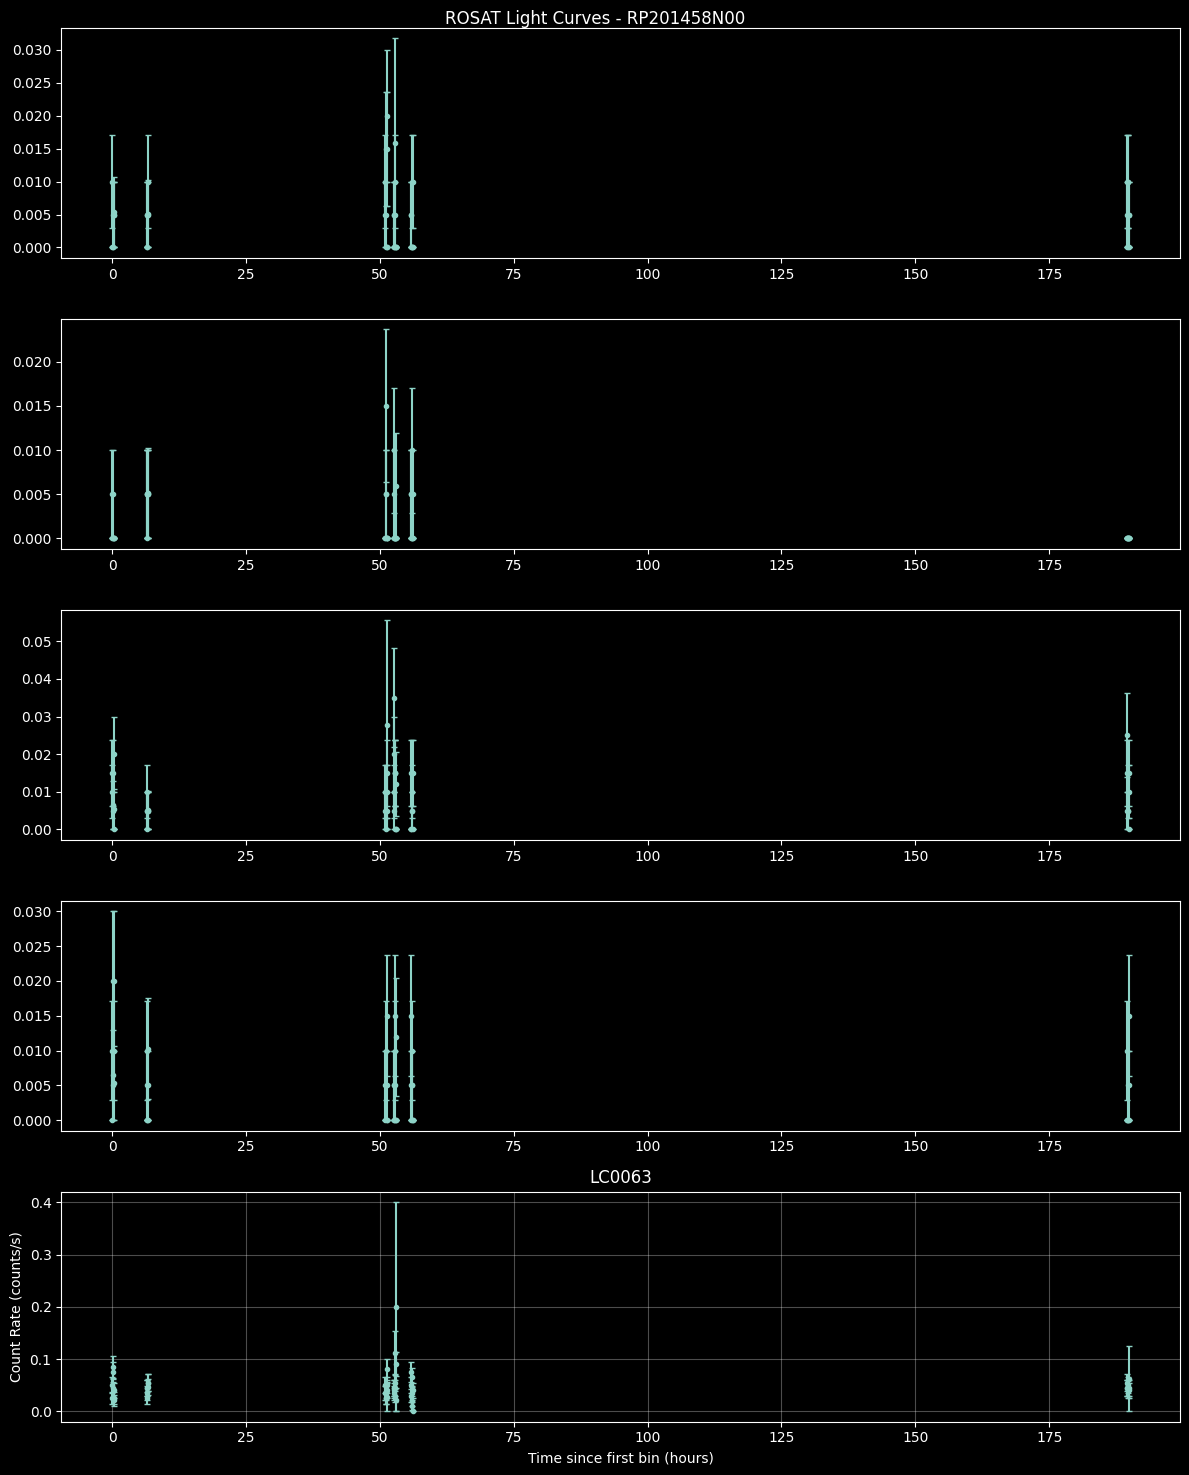

In [10]:

from pathlib import Path
from io import BytesIO

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from unlzw3 import unlzw

# 1. Project folder
folder = Path(
    r"C:\Users\marya\PycharmProjects\PythonProject"
)

# 2. Read observation ID from TXT
txt_path = folder / "ROSATsource.txt"

with open(txt_path, "r") as f:
    lines = f.readlines()

observation_id = lines[1].split()[0]

print("Observation ID:", observation_id)

# 3. Find matching files
matches = [
    p for p in folder.iterdir()
    if p.is_file()
    and observation_id.lower() in p.name.lower()
    and (
        p.name.lower().endswith(".fits")
        or p.name.lower().endswith(".fits.z")
    )
]

print("Matching files:")
for p in matches:
    print(p.name)

if not matches:
    raise FileNotFoundError(
        "No matching FITS files found."
    )

# 4. Open the first valid FITS file
hdul = None

for path in sorted(matches):

    try:
        print("\nTrying:", path.name)

        if path.name.lower().endswith(".z"):

            compressed = path.read_bytes()
            decompressed = unlzw(compressed)

            candidate = fits.open(
                BytesIO(decompressed)
            )

        else:
            candidate = fits.open(path)

        # Force Astropy to read the FITS structure
        candidate.info()

        hdul = candidate
        print("Successfully opened:", path.name)
        break

    except Exception as e:
        print("Could not open:", e)

if hdul is None:
    raise RuntimeError(
        "None of the matching files could be opened."
    )

# 5. Find light curve extensions
try:
    lightcurves = [
        hdu for hdu in hdul
        if isinstance(hdu, fits.BinTableHDU)
        and hdu.data is not None
        and {"TIME", "RATE", "ERROR"}.issubset(
            set(hdu.columns.names)
        )
    ]

    print("\nLight curves found:", len(lightcurves))

    if not lightcurves:
        raise ValueError(
            "No light curve extensions found."
        )

    # 6. Plot all light curves
    fig, axes = plt.subplots(
        len(lightcurves),
        1,
        figsize=(12, 3 * len(lightcurves)),
        squeeze=False
    )

    for ax, hdu in zip(axes[:, 0], lightcurves):

        data = hdu.data

        time = np.asarray(
            data["TIME"], dtype=float
        )

        rate = np.asarray(
            data["RATE"], dtype=float
        )

        error = np.asarray(
            data["ERROR"], dtype=float
        )

        valid = (
            np.isfinite(time)
            & np.isfinite(rate)
            & np.isfinite(error)
            & (error >= 0)
        )

        time = time[valid]
        rate = rate[valid]
        error = error[valid]

        if len(time) == 0:
            ax.set_title(f"{hdu.name}: No valid data")
            continue

        time_hours = (time - time[0]) / 3600

        ax.errorbar(
            time_hours,
            rate,
            yerr=error,
            fmt="o",
            markersize=3,
            capsize=2
        )

    ax.set_title(hdu.name)

    ax.set_xlabel("Time (MJD)")
    ax.set_ylabel("Count Rate (counts/s)")

    # Show MJD numbers under every subplot
    ax.tick_params(axis="x", labelbottom=True)

    ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel(
        "Time since first bin (hours)"
    )

    plt.suptitle(
        f"ROSAT Light Curves - {observation_id}"
    )

    plt.tight_layout()
    plt.show()

finally:
    hdul.close()


X-axis: Elapsed time in hours.

Y-axis: X-ray count rate, number of X-ray photons detected per second.

In [4]:
print("Primary header:")
print(hdul[0].header)

print("\nLight curve header:")
print(hdul["LC0021"].header)

Primary header:
SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                   32 / number of bits per data pixel                  NAXIS   =                    0 / number of data axes                            EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format defined in Astronomy andCOMMENT   Astrophysics Supplement Series v44/p363, v44/p371, v73/p359, v73/p365.COMMENT   Contact the NASA Science Office of Standards and Technology for the   COMMENT   FITS Definition document #100 and other FITS information.             CONTENT = 'LIGHTCURVE'         / SOURCE LIGHTCURVE INFORMATION                  ORIGIN  = 'USRSDC  '           / origin of processed data                       DATE    = '09/05/99'           / FITS creation date (DD/MM/YY)                  TELESCOP= 'ROSAT   '           / mission name                                   INSTRUME= 'PSPCB   '    

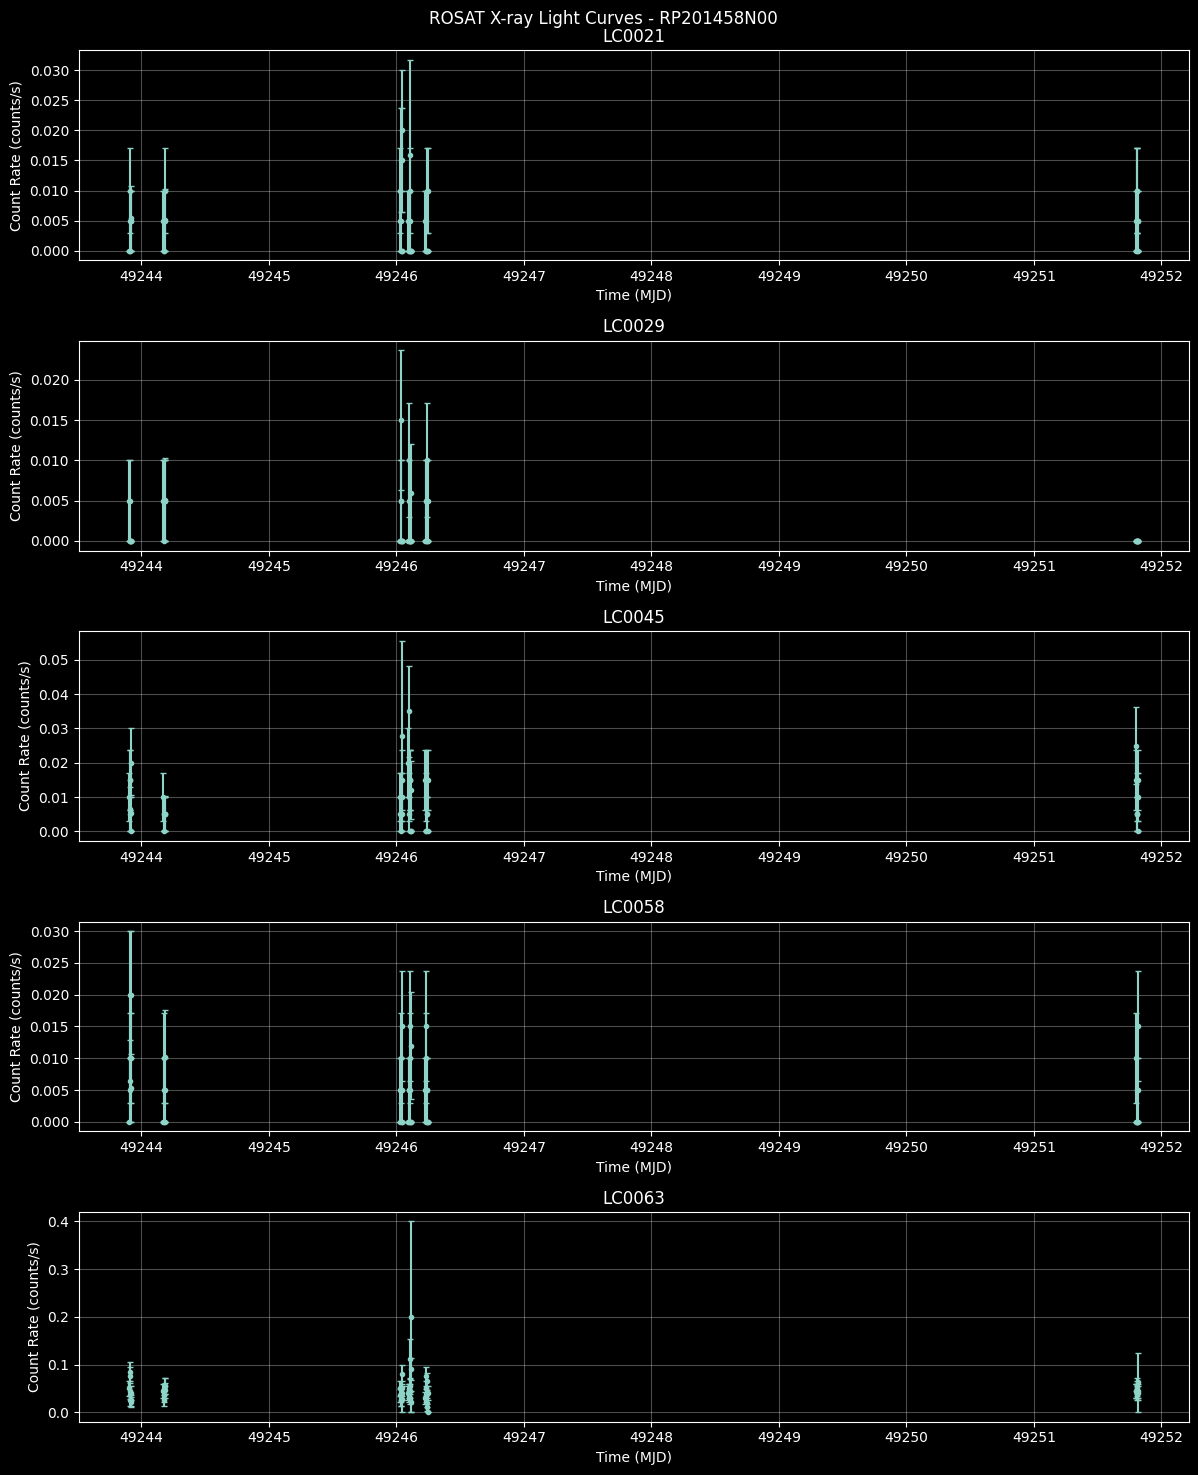

In [14]:

import numpy as np
import matplotlib.pyplot as plt

# Create subplots for all five light curves
fig, axes = plt.subplots(
    len(lightcurves),
    1,
    figsize=(12, 3 * len(lightcurves)),
    sharex=True,
    squeeze=False
)

for ax, hdu in zip(axes[:, 0], lightcurves):

    data = hdu.data
    header = hdu.header

    # Extract light curve measurements
    time = np.asarray(data["TIME"], dtype=float)
    rate = np.asarray(data["RATE"], dtype=float)
    error = np.asarray(data["ERROR"], dtype=float)

    # Read reference MJD and time offset
    mjdref = (
        header["MJDREFI"]
        + header["MJDREFF"]
    )

    timezero = header["TIMEZERO"]

    # Convert ROSAT time to MJD
    time_mjd = mjdref + (timezero + time) / 86400.0

    # Remove invalid measurements
    valid = (
        np.isfinite(time_mjd)
        & np.isfinite(rate)
        & np.isfinite(error)
        & (error >= 0)
    )

    # Plot count rate against MJD
    ax.errorbar(
        time_mjd[valid],
        rate[valid],
        yerr=error[valid],
        fmt="o",
        markersize=3,
        capsize=2
    )

    ax.set_title(hdu.name)
    ax.set_ylabel("Count Rate (counts/s)")
    ax.grid(alpha=0.3)

# Label the shared X-axis
axes[-1, 0].set_xlabel("Time (MJD)")

plt.suptitle(
    "ROSAT X-ray Light Curves - RP201458N00"
)

# Show MJD values and X-axis labels on ALL five graphs
for ax in axes[:, 0]:
    ax.tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=True
    )
    ax.set_xlabel("Time (MJD)")

# Increase space between the graphs
fig.subplots_adjust(hspace=0.6)

plt.tight_layout()
plt.show()


In [9]:
header = hdul["LC0021"].header

for key in [
    "TIMESYS", "TIMEUNIT", "TIMEZERO",
    "MJDREF", "MJDREFI", "MJDREFF",
    "TSTART", "TSTOP", "TUNIT1"
]:
    print(key, "=", header.get(key, "Not present"))

print("First TIME values:")
print(hdul["LC0021"].data["TIME"][:5])
print("First MJD:", time_mjd[0])
print("Last MJD:", time_mjd[-1])

TIMESYS = scc
TIMEUNIT = s
TIMEZERO = 103681788
MJDREF = Not present
MJDREFI = 48043
MJDREFF = 0.879745370373712
TSTART = 103681800.0
TSTOP = 104366000.0
TUNIT1 = s
First TIME values:
[ 410.  610.  810. 1010. 1176.]
First MJD: 49243.90518518519
Last MJD: 49251.819386574076
